In [1]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pprint import pprint

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from scipy.stats import uniform, randint
import joblib

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import optuna



RND = 42
SAVE_DIR = "saved_models_optuna"
os.makedirs(SAVE_DIR, exist_ok=True)


In [2]:
df = pd.read_csv("diabetes_prediction_dataset.csv")
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [3]:
display(df.describe())

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


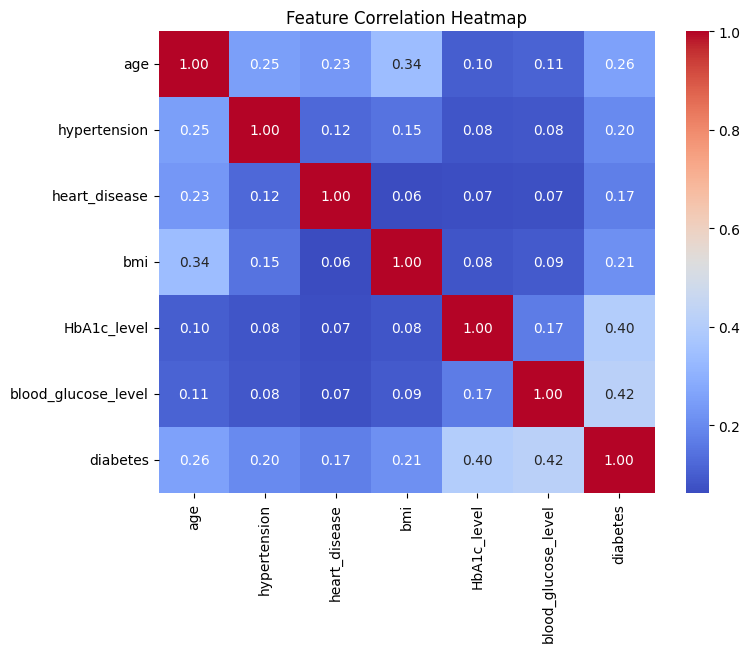

In [4]:
# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Feature Correlation Heatmap")
plt.show()

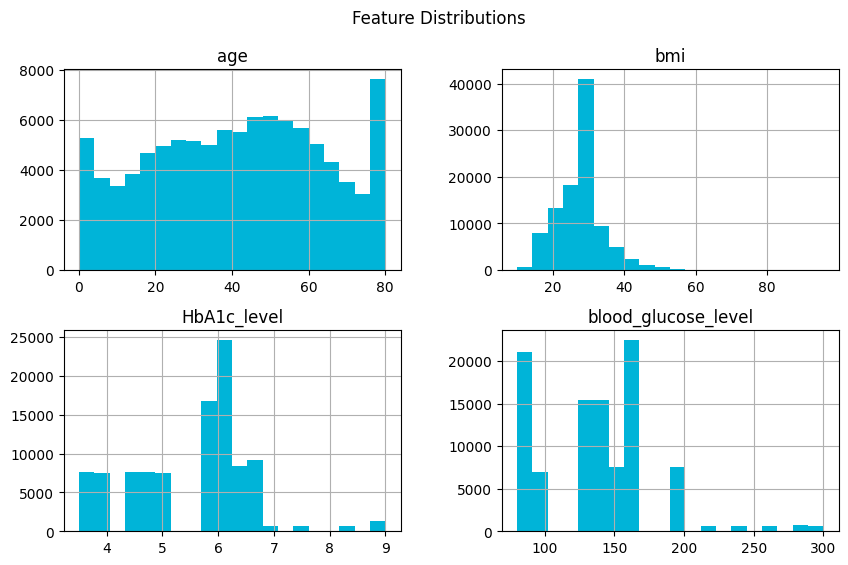

In [5]:
num_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
df[num_cols].hist(figsize=(10,6), bins=20, color='#00b4d8')
plt.suptitle("Feature Distributions")
plt.show()

In [6]:
# --- Gender Encoding (0 = Female, 1 = Male) ---
if 'gender' in df.columns:
    # Normalize gender text (remove spaces, fix capitalization)
    df['gender'] = df['gender'].str.strip().str.capitalize()

    # Replace unexpected values with 'Female' (you can change this logic)
    df.loc[~df['gender'].isin(['Male', 'Female']), 'gender'] = 'Female'

    # Map Female -> 0, Male -> 1
    gender_map = {'Female': 0, 'Male': 1}
    df['gender'] = df['gender'].map(gender_map)

    print(" Gender encoding complete. 0 = Female, 1 = Male")
    print(df['gender'].value_counts())

# --- Smoking History Encoding ---
if 'smoking_history' in df.columns:
    from sklearn.preprocessing import LabelEncoder
    le = LabelEncoder()
    df['smoking_history'] = le.fit_transform(df['smoking_history'].astype(str))
    print("Smoking history classes:", list(le.classes_))

display(df.head())


✅ Gender encoding complete. 0 = Female, 1 = Male
gender
0    58570
1    41430
Name: count, dtype: int64
Smoking history classes: ['No Info', 'current', 'ever', 'former', 'never', 'not current']


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,4,25.19,6.6,140,0
1,0,54.0,0,0,0,27.32,6.6,80,0
2,1,28.0,0,0,4,27.32,5.7,158,0
3,0,36.0,0,0,1,23.45,5.0,155,0
4,1,76.0,1,1,1,20.14,4.8,155,0


In [7]:
# Standardize numeric features
scaler = StandardScaler()
num_features = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
df[num_features] = scaler.fit_transform(df[num_features])

print("\nPreprocessed Data Sample:")
display(df.head())


Preprocessed Data Sample:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,1.692704,0,1,4,-0.321056,1.001706,0.047704,0
1,0,0.538006,0,0,0,-0.000116,1.001706,-1.426210,0
2,1,-0.616691,0,0,4,-0.000116,0.161108,0.489878,0
3,0,-0.261399,0,0,1,-0.583232,-0.492690,0.416183,0
4,1,1.515058,1,1,1,-1.081970,-0.679490,0.416183,0


In [8]:
# 5. TRAIN-TEST SPLIT + SMOTE
# ============================================================
X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RND
)
print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (80000, 8) Test: (20000, 8)


In [9]:
# Handle imbalance
smote = SMOTE(random_state=RND)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
print("\nAfter SMOTE balance:\n", pd.Series(y_train_sm).value_counts())




After SMOTE balance:
 diabetes
1    73200
0    73200
Name: count, dtype: int64


In [10]:
# 6. HELPER FUNCTION
def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    print(f"\n{name} Evaluation:")
    print(classification_report(y_test, y_pred, digits=4))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    return {"accuracy": acc, "f1": f1, "precision": prec, "recall": rec}

=== Logistic Regression ===

Logistic Regression Evaluation:
              precision    recall  f1-score   support

           0     0.9886    0.8852    0.9341     18300
           1     0.4188    0.8906    0.5697      1700

    accuracy                         0.8857     20000
   macro avg     0.7037    0.8879    0.7519     20000
weighted avg     0.9402    0.8857    0.9031     20000



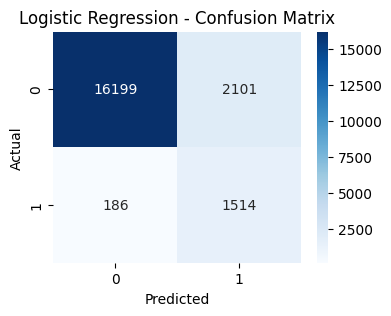

['saved_models_optuna/best_lr.joblib']

In [11]:
#7. MODEL TRAINING
# ============================================================
results = {}

# Logistic Regression
print("=== Logistic Regression ===")
lr = LogisticRegression(max_iter=1000, random_state=RND)
params = {'C':[0.01,0.1,1,10], 'solver':['liblinear']}
gs_lr = GridSearchCV(lr, params, cv=3, scoring='f1', n_jobs=-1)
gs_lr.fit(X_train_sm, y_train_sm)
best_lr = gs_lr.best_estimator_
results['LogisticRegression'] = evaluate_model(best_lr, X_test, y_test, "Logistic Regression")
joblib.dump(best_lr, f"{SAVE_DIR}/best_lr.joblib")


=== KNN ===

KNN Evaluation:
              precision    recall  f1-score   support

           0     0.9786    0.9385    0.9581     18300
           1     0.5406    0.7794    0.6384      1700

    accuracy                         0.9250     20000
   macro avg     0.7596    0.8589    0.7983     20000
weighted avg     0.9414    0.9250    0.9310     20000



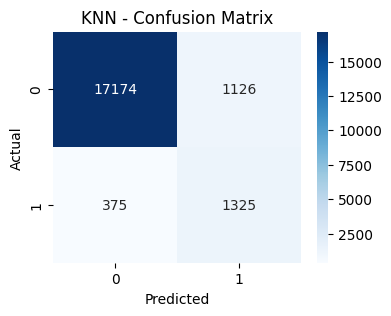

['saved_models_optuna/best_knn.joblib']

In [12]:
# KNN
print("=== KNN ===")
knn = KNeighborsClassifier()
params = {'n_neighbors':[3,5,7], 'weights':['uniform','distance']}
gs_knn = GridSearchCV(knn, params, cv=3, scoring='f1', n_jobs=-1)
gs_knn.fit(X_train_sm, y_train_sm)
best_knn = gs_knn.best_estimator_
results['KNN'] = evaluate_model(best_knn, X_test, y_test, "KNN")
joblib.dump(best_knn, f"{SAVE_DIR}/best_knn.joblib")

=== RandomForest ===

Random Forest Evaluation:
              precision    recall  f1-score   support

           0     0.9766    0.9789    0.9777     18300
           1     0.7666    0.7476    0.7570      1700

    accuracy                         0.9592     20000
   macro avg     0.8716    0.8632    0.8674     20000
weighted avg     0.9588    0.9592    0.9590     20000



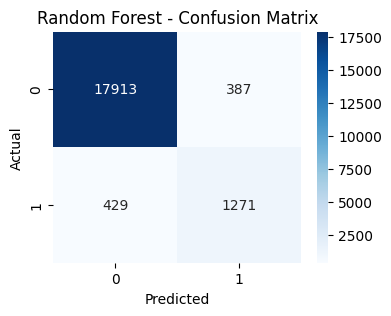

['saved_models_optuna/best_rf.joblib']

In [13]:
# RandomForest
print("=== RandomForest ===")
rf = RandomForestClassifier(random_state=RND)
params = {'n_estimators':[100,200], 'max_depth':[10,20,None]}
gs_rf = GridSearchCV(rf, params, cv=3, scoring='f1', n_jobs=-1)
gs_rf.fit(X_train_sm, y_train_sm)
best_rf = gs_rf.best_estimator_
results['RandomForest'] = evaluate_model(best_rf, X_test, y_test, "Random Forest")
joblib.dump(best_rf, f"{SAVE_DIR}/best_rf.joblib")

=== XGBoost ===

XGBoost Evaluation:
              precision    recall  f1-score   support

           0     0.9747    0.9923    0.9834     18300
           1     0.8970    0.7224    0.8003      1700

    accuracy                         0.9694     20000
   macro avg     0.9358    0.8573    0.8918     20000
weighted avg     0.9681    0.9694    0.9678     20000



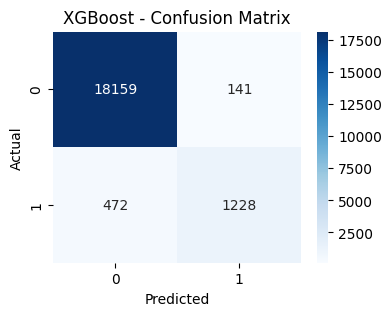

['saved_models_optuna/best_xgb.joblib']

In [14]:
print("=== XGBoost ===")
xgb = XGBClassifier(
    eval_metric='logloss',  # keep this!
    random_state=RND,
    verbosity=0
)
params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 6],
    'learning_rate': [0.01, 0.1]
}
gs_xgb = GridSearchCV(xgb, params, cv=3, scoring='f1', n_jobs=-1)
gs_xgb.fit(X_train_sm, y_train_sm)
best_xgb = gs_xgb.best_estimator_
results['XGBoost'] = evaluate_model(best_xgb, X_test, y_test, "XGBoost")
joblib.dump(best_xgb, f"{SAVE_DIR}/best_xgb.joblib")


=== CatBoost ===

CatBoost Evaluation:
              precision    recall  f1-score   support

           0     0.9733    0.9961    0.9846     18300
           1     0.9434    0.7059    0.8075      1700

    accuracy                         0.9714     20000
   macro avg     0.9583    0.8510    0.8960     20000
weighted avg     0.9708    0.9714    0.9695     20000



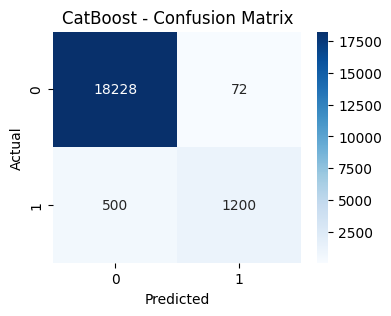

['saved_models_optuna/best_cat.joblib']

In [15]:
print("=== CatBoost ===")
cat = CatBoostClassifier(verbose=0, random_state=RND, allow_writing_files=False)
params = {'iterations':[100,200], 'depth':[4,6], 'learning_rate':[0.01,0.1]}

gs_cat = GridSearchCV(cat, params, cv=3, scoring='f1', n_jobs=1, error_score='raise')
gs_cat.fit(X_train_sm, y_train_sm)

best_cat = gs_cat.best_estimator_
results['CatBoost'] = evaluate_model(best_cat, X_test, y_test, "CatBoost")
joblib.dump(best_cat, f"{SAVE_DIR}/best_cat.joblib")


=== GaussianNB ===

GaussianNB Evaluation:
              precision    recall  f1-score   support

           0     0.9784    0.8975    0.9362     18300
           1     0.4161    0.7865    0.5443      1700

    accuracy                         0.8881     20000
   macro avg     0.6972    0.8420    0.7402     20000
weighted avg     0.9306    0.8881    0.9029     20000



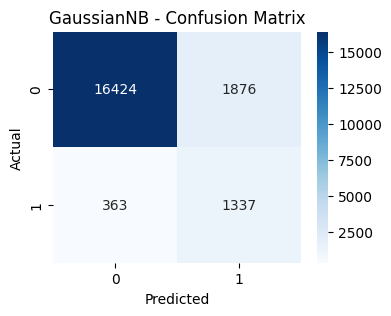

['saved_models_optuna/best_gnb.joblib']

In [16]:
# GaussianNB
print("=== GaussianNB ===")
gnb = GaussianNB()
params = {'var_smoothing': np.logspace(-9,-6,4)}
gs_gnb = GridSearchCV(gnb, params, cv=3, scoring='f1', n_jobs=-1)
gs_gnb.fit(X_train_sm, y_train_sm)
best_gnb = gs_gnb.best_estimator_
results['GaussianNB'] = evaluate_model(best_gnb, X_test, y_test, "GaussianNB")
joblib.dump(best_gnb, f"{SAVE_DIR}/best_gnb.joblib")


,Accuracy,F1-Score,Precision,Recall
CatBoost,0.9714,0.8075,0.9434,0.7059
XGBoost,0.9694,0.8003,0.8970,0.7224
RandomForest,0.9592,0.7570,0.7666,0.7476
KNN,0.9250,0.6384,0.5406,0.7794
GaussianNB,0.8880,0.5443,0.4161,0.7865
LogisticRegression,0.8856,0.5697,0.4188,0.8906


<Figure size 1000x600 with 0 Axes>

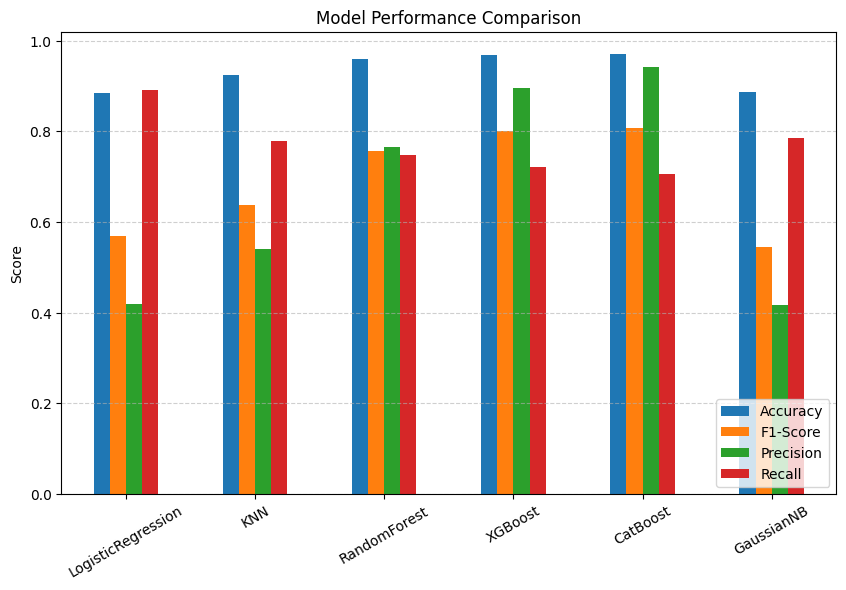

In [17]:

# 8. RESULTS SUMMARY 

# Build a DataFrame with all metrics: Accuracy, F1, Precision, Recall
summary_df = pd.DataFrame({
    model: {
        'Accuracy': metrics['accuracy'],
        'F1-Score': metrics['f1'],
        'Precision': metrics['precision'],
        'Recall': metrics['recall']
    }
    for model, metrics in results.items()
}).T  # transpose to make models as rows

# Round for clean display
summary_df = summary_df.round(4)
display(summary_df.sort_values('Accuracy', ascending=False))

# Bar plots for visual comparison
plt.figure(figsize=(10,6))
summary_df[['Accuracy','F1-Score','Precision','Recall']].plot(kind='bar', figsize=(10,6))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()



🏆 Best Classical Model: CatBoost
Saved final best model as: saved_models_optuna/best_overall_model_CatBoost.joblib

=== Best Model Performance Metrics ===


,Accuracy,F1-Score,Precision,Recall
CatBoost,0.9714,0.8075,0.9434,0.7059


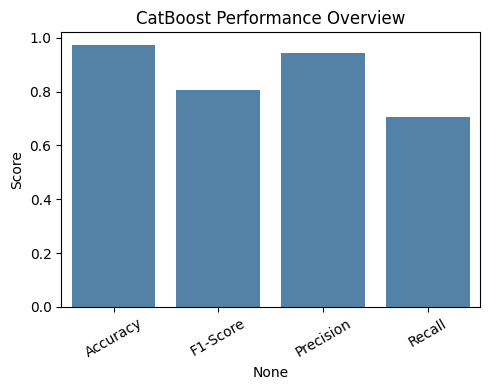

In [22]:
# 10. FINAL BEST MODEL SELECTION (Corrected and Clean)
# Find the best classical model based on Accuracy
best_model_name = summary_df['Accuracy'].idxmax()   # <-- Capital 'A'
print("\nBest Classical Model:", best_model_name)

# Retrieve the corresponding trained model object
best_model = {
    'LogisticRegression': best_lr,
    'KNN': best_knn,
    'RandomForest': best_rf,
    'XGBoost': best_xgb,
    'CatBoost': best_cat,
    'GaussianNB': best_gnb
}[best_model_name]

# Save the chosen best model
best_model_path = f"{SAVE_DIR}/best_overall_model_{best_model_name}.joblib"
joblib.dump(best_model, best_model_path)

# Print summary
print(f"Saved final best model as: {best_model_path}")

# Display best model's metrics clearly
print("\n=== Best Model Performance Metrics ===")
display(summary_df.loc[[best_model_name]])
plt.figure(figsize=(5,4))
sns.barplot(x=best_metrics.index, y=best_metrics.values, color='#4682B4')  # blue tone
plt.title(f"{best_model_name} Performance Overview")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [23]:
from sklearn.preprocessing import StandardScaler
import joblib

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

joblib.dump(scaler, "saved_models_optuna/scaler.joblib")


['saved_models_optuna/scaler.joblib']